In [53]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/jonnawaddington/Documents/DataAnalysis/Data-Analysis-with-Python-Case-Studies/sales_forecasting_data.csv', parse_dates=["date"])
df = df.sort_values("date")
print(df.head())

          date  store_id   sales  promotion  holiday  weekday
0   2020-01-01         3  114.90          0        0        2
31  2020-01-02         2  169.90          0        0        5
60  2020-01-03         3   95.97          0        0        6
91  2020-01-04         3  181.02          0        0        2
121 2020-01-05         1   99.23          1        1        4


/var/folders/4l/y7_bfnmx49g7x7l02z6ghf1m0000gn/T/ipykernel_20699/1328694466.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('/Users/jonnawaddington/Documents/DataAnalysis/Data-Analysis-with-Python-Case-Studies/sales_forecasting_data.csv', parse_dates=["date"])


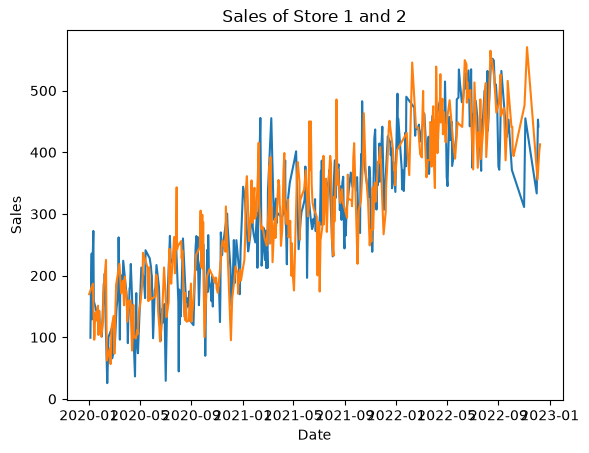

In [54]:
store1 = df[df["store_id"] == 1]
store2 = df[df["store_id"] == 2]
store3 = df[df["store_id"] == 3]

plt.plot(store1["date"], store1["sales"])
plt.plot(store2["date"], store2["sales"])

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales of Store 1 and 2")
plt.show()

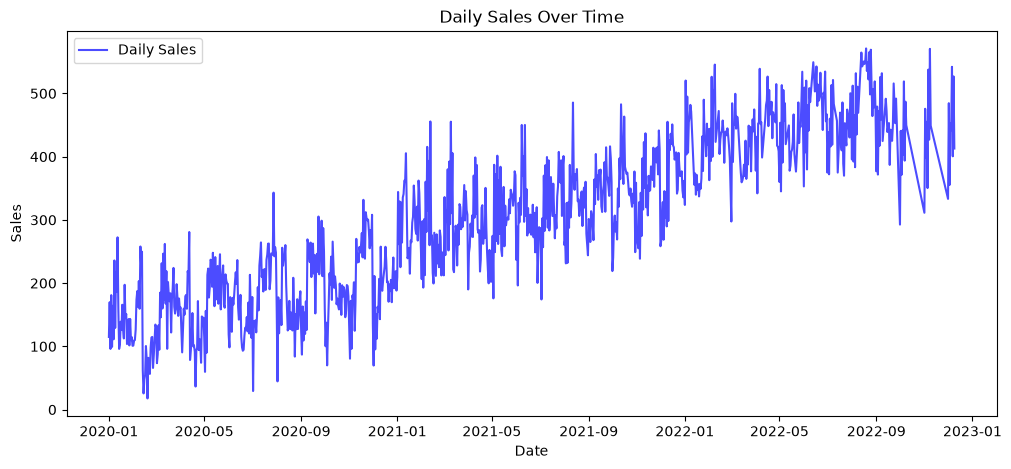

In [55]:
# Plot sales trends
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["sales"], label="Daily Sales", color='blue', alpha=0.7)
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Daily Sales Over Time")
plt.legend()
plt.show()

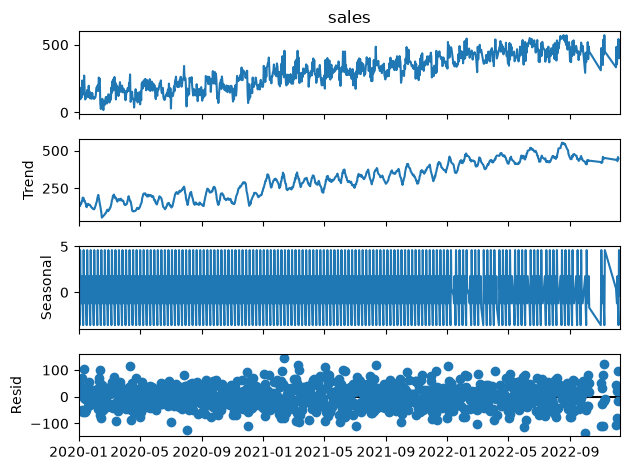

In [56]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform time series decomposition
decomposition = seasonal_decompose(df.set_index("date")["sales"], model="additive", period=7)

# Plot components
decomposition.plot()
plt.show()

# Moving average for a daily sale (liukuva keskiarvo). 

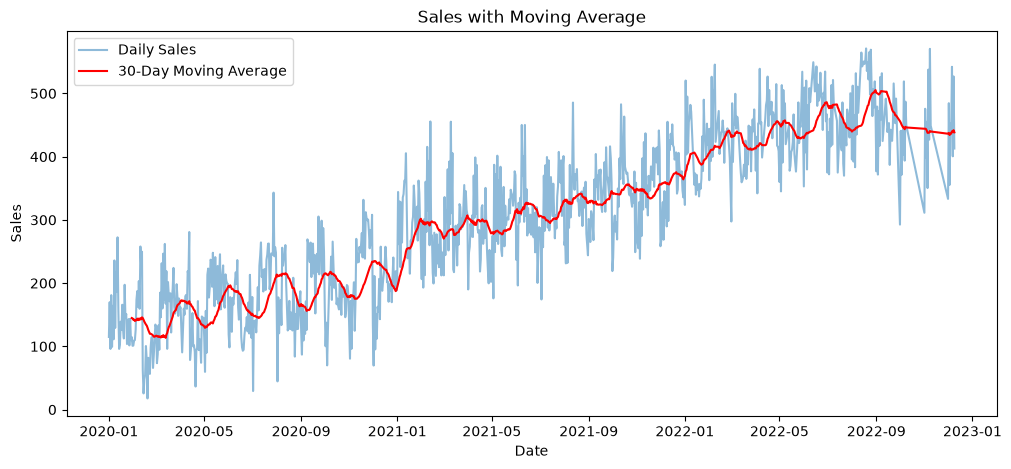

In [57]:
df["moving_avg"] = df["sales"].rolling(window=30).mean()

# Plot sales and moving average
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["sales"], label="Daily Sales", alpha=0.5)
plt.plot(df["date"], df["moving_avg"], label="30-Day Moving Average", color='red')
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales with Moving Average")
plt.legend()
plt.show()

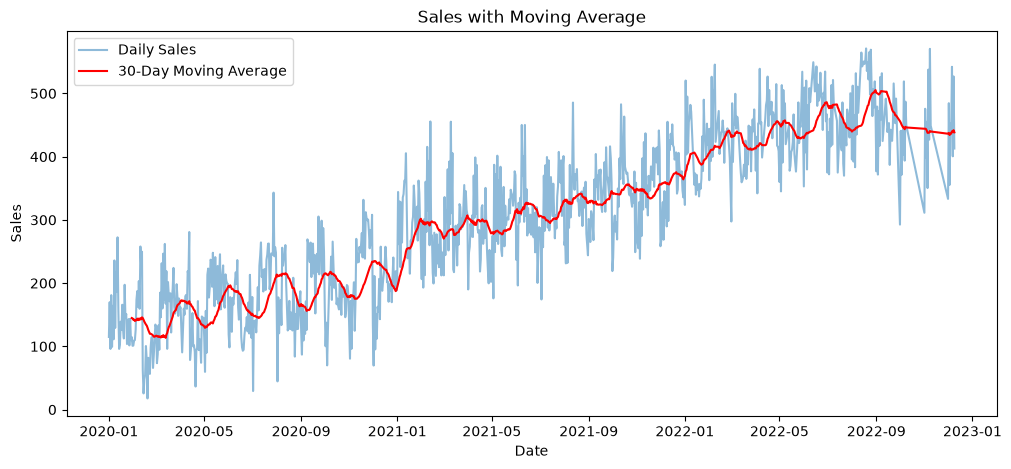

In [58]:
df["moving_avg"] = df["sales"].rolling(window=30).mean()

# Plot sales and moving average
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["sales"], label="Daily Sales", alpha=0.5)
plt.plot(df["date"], df["moving_avg"], label="30-Day Moving Average", color='red')
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales with Moving Average")
plt.legend()
plt.show()

# Exploratory Data Analysis (EDA)

### Examine historical sales trends across different stores.

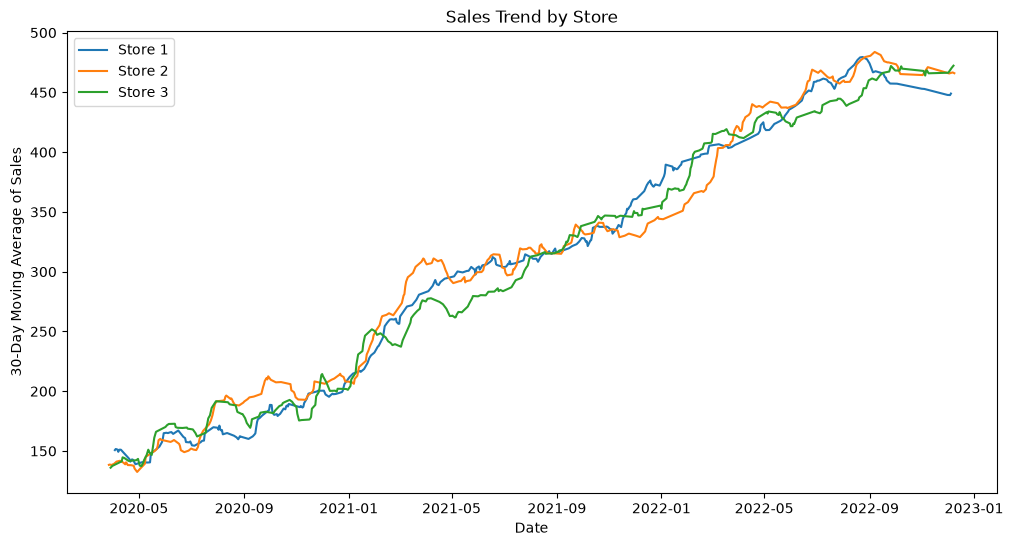

In [59]:
plt.figure(figsize=(12, 6))

for store, data in df.groupby("store_id"):
    data = data.sort_values("date")
    plt.plot(data["date"], data["sales"].rolling(window=30).mean(), label=f"Store {store}")

plt.xlabel("Date")
plt.ylabel("30-Day Moving Average of Sales")
plt.title("Sales Trend by Store")
plt.legend()
plt.show()


### Identify outliers, missing values, and data inconsistencies.

### Visualize patterns to detect seasonality, trends, and anomalies.